# DAIC-WOZ eGeMAPS exploratory analysis

This adapts the TORGO notebook's data checks, feature-distribution plots, PCA, and random-forest analysis to DAIC-WOZ. Each row is one participant-answer segment's eGeMAPSv02 functionals. The model trains on the official train split and evaluates on the separate dev split, so participants are not mixed across train and test. This is exploratory analysis, not a clinical assessment.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
TRAIN_CSV_PATH = Path("data/processed/daicwoz_train_egemaps.csv")
DEV_CSV_PATH = Path("data/processed/daicwoz_dev_egemaps.csv")
if not TRAIN_CSV_PATH.exists():
    TRAIN_CSV_PATH = Path("../data/processed/daicwoz_train_egemaps.csv")
if not DEV_CSV_PATH.exists():
    DEV_CSV_PATH = Path("../data/processed/daicwoz_dev_egemaps.csv")
for csv_path in (TRAIN_CSV_PATH, DEV_CSV_PATH):
    if not csv_path.is_file():
        raise FileNotFoundError(
            f"Could not find {csv_path}. Extract both train and dev features first."
        )

train_df = pd.read_csv(TRAIN_CSV_PATH)
dev_df = pd.read_csv(DEV_CSV_PATH)
train_df["split"] = "train"
dev_df["split"] = "dev"
df = pd.concat([train_df, dev_df], ignore_index=True)
df.head()

## 1. Check the extracted data

The number of feature columns can vary with openSMILE versions/configuration. Check the actual shape and missing values rather than assuming a fixed column count.

In [2]:
metadata_cols = {"participant_id", "audio_file", "label"}
feature_cols = [
    column for column in df.select_dtypes(include=np.number).columns
    if column not in metadata_cols
]
print("Shape:", df.shape)
print("Participants:", df["participant_id"].nunique())
print("eGeMAPS feature count:", len(feature_cols))
print("\nMissing values by column (nonzero only):")
print(df.isna().sum().loc[lambda counts: counts > 0])
if "label" in df:
    print("\nClass distribution (0 = below threshold, 1 = at/above threshold):")
    print(df["label"].value_counts(dropna=False).sort_index())

if not feature_cols:
    raise ValueError("No numeric eGeMAPS feature columns were found.")

Shape: (8080, 92)
Participants: 142
eGeMAPS feature count: 88

Missing values by column (nonzero only):
Series([], dtype: int64)

Class distribution (0 = below threshold, 1 = at/above threshold):
label
0    5587
1    2493
Name: count, dtype: int64


## 2. Visualize selected feature distributions

Compare a few familiar pitch, loudness, voice-quality, and spectral features across the binary PHQ-8 label. Only columns that exist in this openSMILE output are plotted.

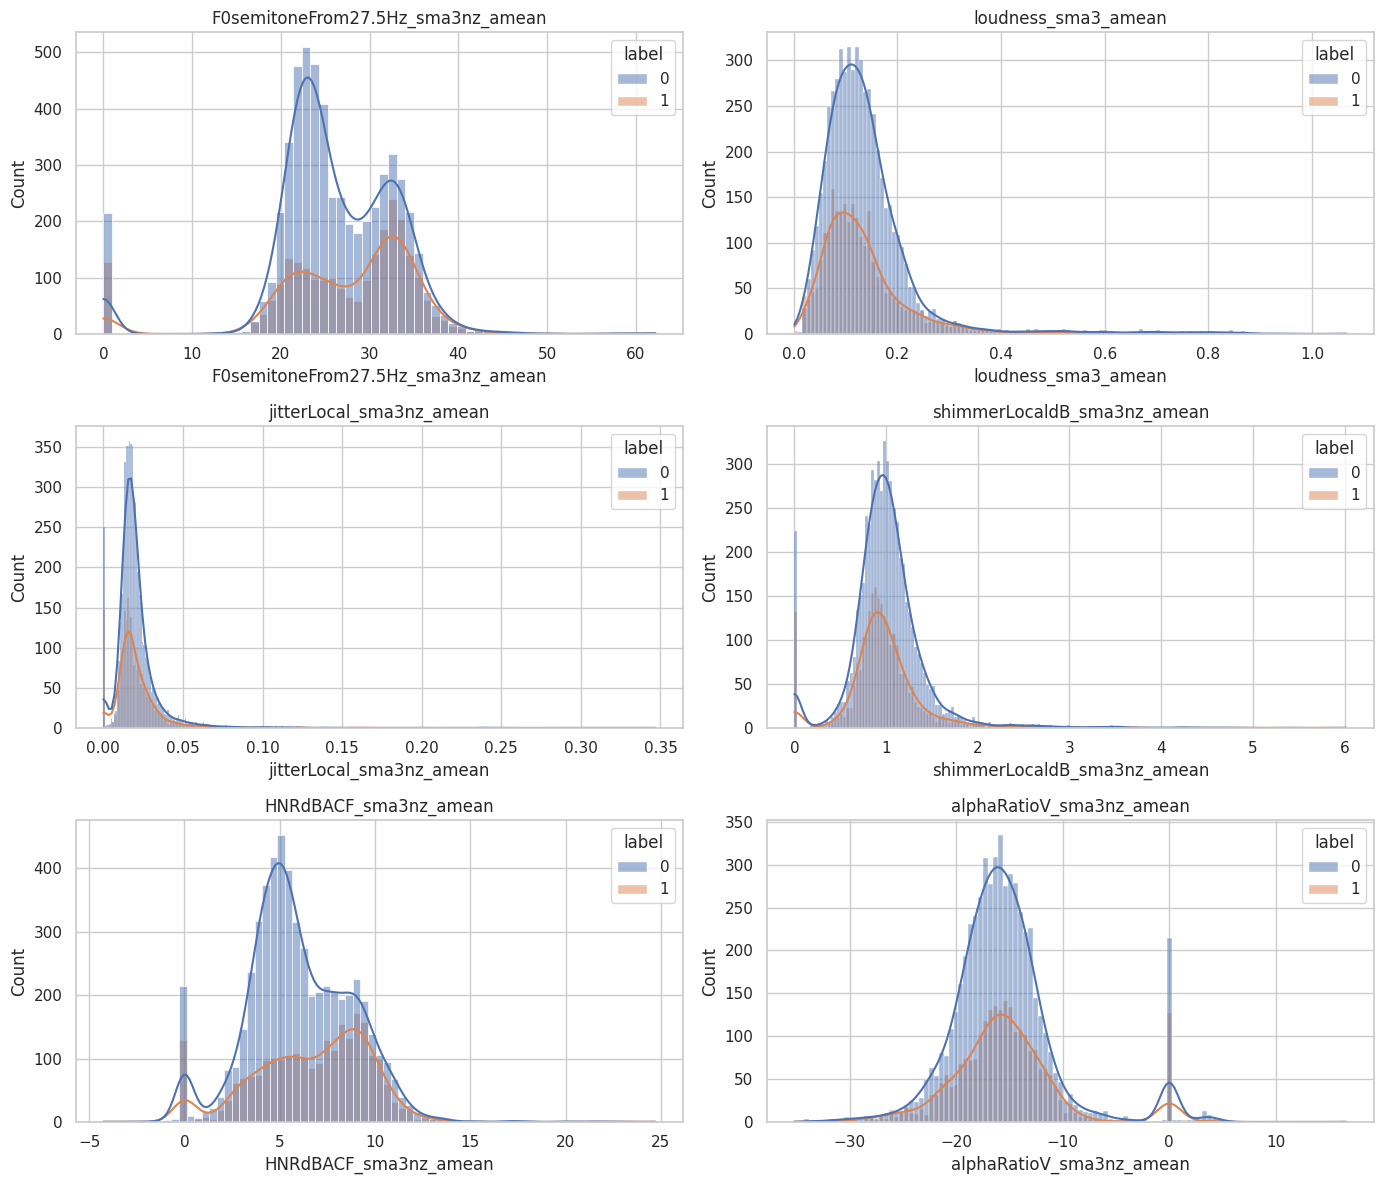

In [3]:
preferred_features = [
    "F0semitoneFrom27.5Hz_sma3nz_amean",
    "loudness_sma3_amean",
    "jitterLocal_sma3nz_amean",
    "shimmerLocaldB_sma3nz_amean",
    "HNRdBACF_sma3nz_amean",
    "alphaRatioV_sma3nz_amean",
]
plot_features = [name for name in preferred_features if name in feature_cols]
if not plot_features:
    plot_features = feature_cols[: min(6, len(feature_cols))]

if "label" not in df or df["label"].dropna().nunique() < 2:
    print("Two labeled classes are required for class-wise plots.")
else:
    plot_data = df.dropna(subset=["label"])
    fig, axes = plt.subplots(
        nrows=(len(plot_features) + 1) // 2,
        ncols=2,
        figsize=(14, 4 * ((len(plot_features) + 1) // 2)),
        squeeze=False,
    )
    for ax, feature in zip(axes.flat, plot_features):
        sns.histplot(data=plot_data, x=feature, hue="label", kde=True, ax=ax)
        ax.set_title(feature)
    for ax in axes.flat[len(plot_features):]:
        ax.remove()
    plt.tight_layout()
    plt.show()

## 3. PCA visualization

Standardize the features before projecting them to two dimensions. Median imputation keeps rows with a small number of missing feature values available for visualization.

In [4]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

pca_data = df.dropna(subset=["label"]).copy()
if pca_data["label"].nunique() >= 2 and len(feature_cols) >= 2:
    X_pca = SimpleImputer(strategy="median").fit_transform(pca_data[feature_cols])
    X_pca = StandardScaler().fit_transform(X_pca)
    pca = PCA(n_components=2, random_state=42)
    coordinates = pca.fit_transform(X_pca)
    pca_data["PC1"] = coordinates[:, 0]
    pca_data["PC2"] = coordinates[:, 1]
    print("Variance explained by first two components:", pca.explained_variance_ratio_.sum())
    sns.scatterplot(data=pca_data, x="PC1", y="PC2", hue="label", alpha=0.8)
    plt.title("PCA of eGeMAPS features")
    plt.show()
else:
    print("Need at least two labeled classes and two numeric features for PCA.")

Variance explained by first two components: 0.3326453756862257


## 4. Random forest: official train/dev evaluation

The CSVs contain multiple segments per participant. Train only on the official train feature file and evaluate on the official dev feature file. Verify that participant IDs do not overlap; otherwise stop rather than reporting a leaked evaluation. The number of participants is limited, so treat these metrics as exploratory.

Train rows/participants: 6218 107
Dev rows/participants: 1862 35
Train class counts:
 label
0    4437
1    1781
Name: count, dtype: int64
Test class counts:
 label
0    1150
1     712
Name: count, dtype: int64



Balanced accuracy: 0.4859171958964338

                     precision    recall  f1-score   support

   below threshold       0.61      0.93      0.74      1150
at/above threshold       0.26      0.04      0.07       712

          accuracy                           0.59      1862
         macro avg       0.44      0.49      0.40      1862
      weighted avg       0.48      0.59      0.48      1862



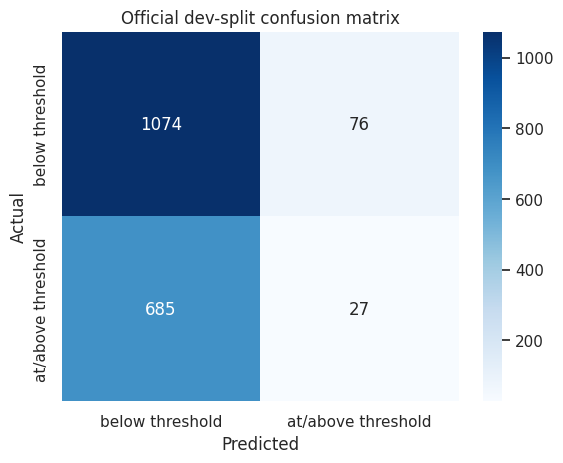

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix
from sklearn.pipeline import make_pipeline

train_model_data = train_df.dropna(subset=["label", "participant_id"]).copy()
dev_model_data = dev_df.dropna(subset=["label", "participant_id"]).copy()
train_model_data["label"] = pd.to_numeric(train_model_data["label"], errors="raise").astype(int)
dev_model_data["label"] = pd.to_numeric(dev_model_data["label"], errors="raise").astype(int)
train_people = set(train_model_data["participant_id"].astype(str))
dev_people = set(dev_model_data["participant_id"].astype(str))
overlap = train_people & dev_people
if overlap:
    raise ValueError(f"Train/dev participant overlap ({len(overlap)} IDs); refusing leaked evaluation.")
if train_model_data["label"].nunique() != 2 or dev_model_data["label"].nunique() != 2:
    raise ValueError("Both train and dev need labeled examples from both classes (0 and 1).")

X_train = train_model_data[feature_cols]
X_test = dev_model_data[feature_cols]
y_train = train_model_data["label"]
y_test = dev_model_data["label"]
print("Train rows/participants:", len(train_model_data), len(train_people))
print("Dev rows/participants:", len(dev_model_data), len(dev_people))
print("Train class counts:\n", y_train.value_counts().sort_index())
print("Test class counts:\n", y_test.value_counts().sort_index())

model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print("\nBalanced accuracy:", balanced_accuracy_score(y_test, predictions))
print("\n", classification_report(
    y_test,
    predictions,
    labels=[0, 1],
    target_names=["below threshold", "at/above threshold"],
    zero_division=0,
))
sns.heatmap(
    confusion_matrix(y_test, predictions, labels=[0, 1]),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["below threshold", "at/above threshold"],
    yticklabels=["below threshold", "at/above threshold"],
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Official dev-split confusion matrix")
plt.show()

## 5. Feature importance

Random-forest impurity importances are a quick descriptive summary. Correlated acoustic features can split importance across columns, so do not interpret this ranking as causal evidence.

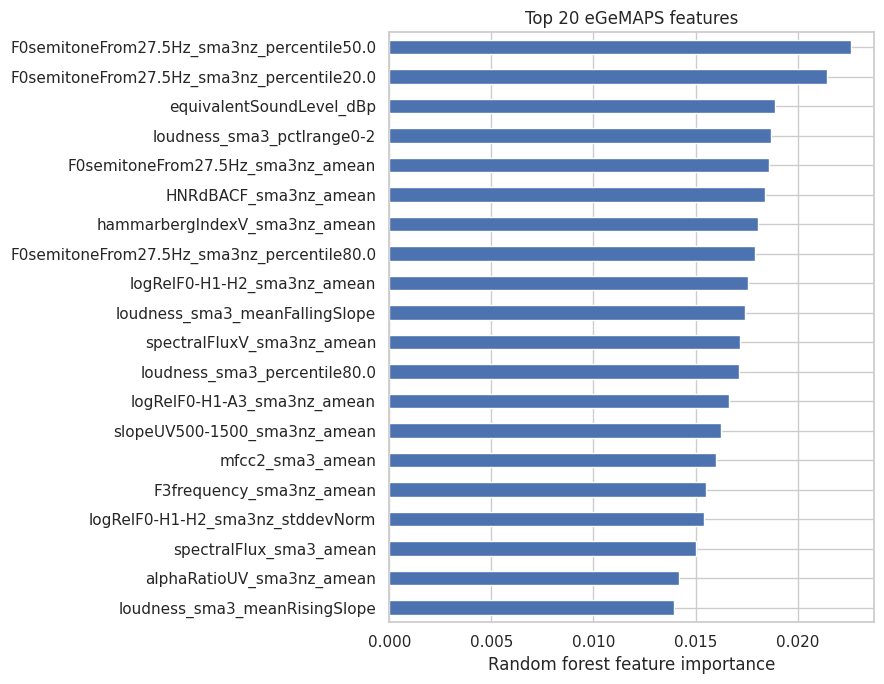

In [6]:
forest = model.named_steps["randomforestclassifier"]
importance = pd.Series(forest.feature_importances_, index=feature_cols)
importance.nlargest(20).sort_values().plot.barh(figsize=(9, 7))
plt.xlabel("Random forest feature importance")
plt.title("Top 20 eGeMAPS features")
plt.tight_layout()
plt.show()